<a href="https://colab.research.google.com/github/Sharjeelsarwar-ai2/decode-labs-internship/blob/main/Classification_Model(Decode_labs).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
iris = load_iris(as_frame=True)
df = iris.frame
df["species"] = df["target"].map(dict(enumerate(iris.target_names)))

print("Dataset shape (rows, columns):", df.shape)
df.head()

Dataset shape (rows, columns): (150, 6)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [3]:
print(df["species"].value_counts())
print()
print(df.describe().round(2))

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count             150.00            150.00             150.00   
mean                5.84              3.06               3.76   
std                 0.83              0.44               1.77   
min                 4.30              2.00               1.00   
25%                 5.10              2.80               1.60   
50%                 5.80              3.00               4.35   
75%                 6.40              3.30               5.10   
max                 7.90              4.40               6.90   

       petal width (cm)  target  
count            150.00  150.00  
mean               1.20    1.00  
std                0.76    0.82  
min                0.10    0.00  
25%                0.30    0.00  
50%                1.30    1.00  
75%                1.80    2.00  
max                2.50    2.00  


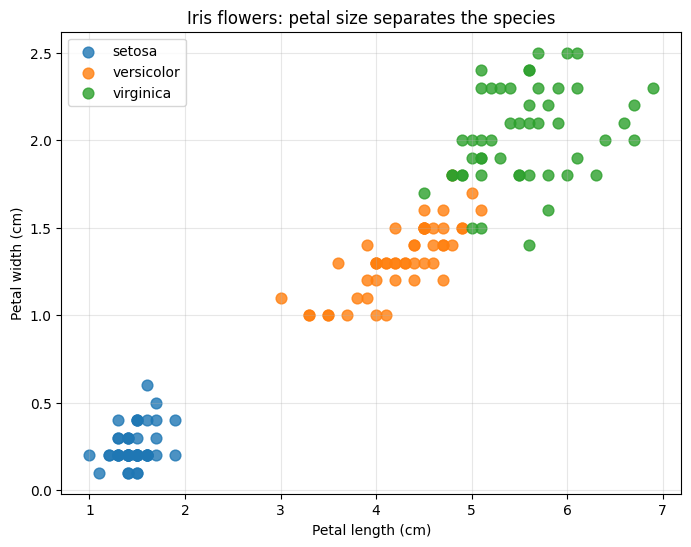

In [4]:
colors = {"setosa": "tab:blue", "versicolor": "tab:orange", "virginica": "tab:green"}
plt.figure(figsize=(8, 6))
for species, group in df.groupby("species"):
    plt.scatter(group["petal length (cm)"], group["petal width (cm)"],
                label=species, color=colors[species], s=60, alpha=0.8)
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.title("Iris flowers: petal size separates the species")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [5]:
X = df[iris.feature_names]   # the 4 measurements (the INPUTS)
y = df["target"]             # the species number 0, 1, 2 (the ANSWER)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Training set:", X_train.shape, "-> the model LEARNS from these")
print("Test set:    ", X_test.shape, "-> the model is TESTED on these (never seen)")

Training set: (120, 4) -> the model LEARNS from these
Test set:     (30, 4) -> the model is TESTED on these (never seen)


In [6]:
tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_train, y_train)

predictions = tree.predict(X_test)
print("Decision Tree accuracy:", round(accuracy_score(y_test, predictions), 4))
print("That means", (predictions == y_test.values).sum(), "correct out of", len(y_test))

Decision Tree accuracy: 0.9333
That means 28 correct out of 30


In [7]:
print("Confusion matrix  (rows = true species, columns = predicted species)")
print(confusion_matrix(y_test, predictions))
print()
print(classification_report(y_test, predictions, target_names=iris.target_names))

Confusion matrix  (rows = true species, columns = predicted species)
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [8]:
print(export_text(tree, feature_names=iris.feature_names, max_depth=3))

|--- petal length (cm) <= 2.45
|   |--- class: 0
|--- petal length (cm) >  2.45
|   |--- petal width (cm) <= 1.65
|   |   |--- petal length (cm) <= 4.95
|   |   |   |--- class: 1
|   |   |--- petal length (cm) >  4.95
|   |   |   |--- sepal length (cm) <= 6.15
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- sepal length (cm) >  6.15
|   |   |   |   |--- class: 2
|   |--- petal width (cm) >  1.65
|   |   |--- petal length (cm) <= 4.85
|   |   |   |--- sepal width (cm) <= 3.00
|   |   |   |   |--- class: 2
|   |   |   |--- sepal width (cm) >  3.00
|   |   |   |   |--- class: 1
|   |   |--- petal length (cm) >  4.85
|   |   |   |--- class: 2



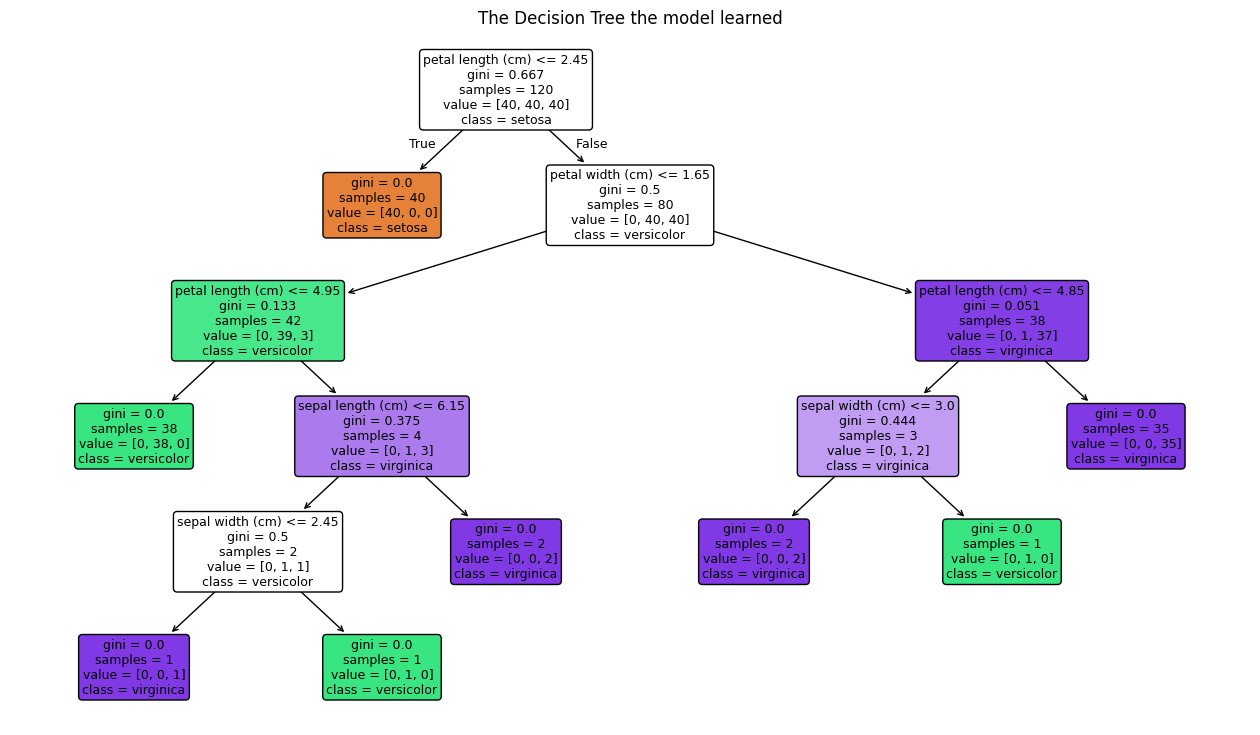

In [9]:
plt.figure(figsize=(16, 9))
plot_tree(tree, feature_names=iris.feature_names,
          class_names=list(iris.target_names),
          filled=True, rounded=True, fontsize=9)
plt.title("The Decision Tree the model learned")
plt.show()

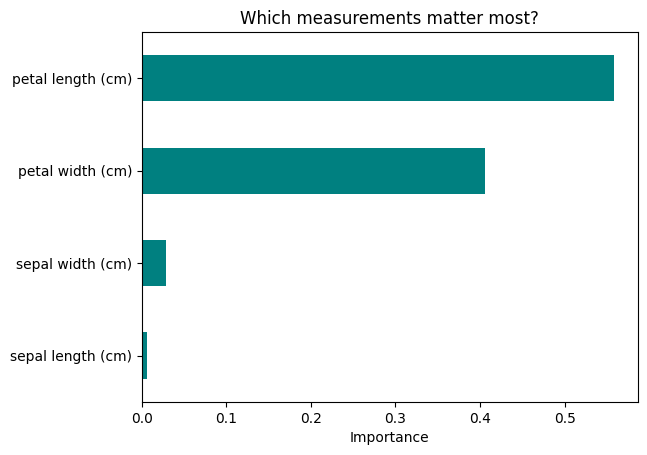

In [10]:
importances = pd.Series(tree.feature_importances_, index=iris.feature_names)
importances.sort_values().plot(kind="barh", color="teal")
plt.xlabel("Importance")
plt.title("Which measurements matter most?")
plt.show()

Decision Tree          accuracy = 0.9333
KNN (k=5)              accuracy = 1.0000
Logistic Regression    accuracy = 0.9667


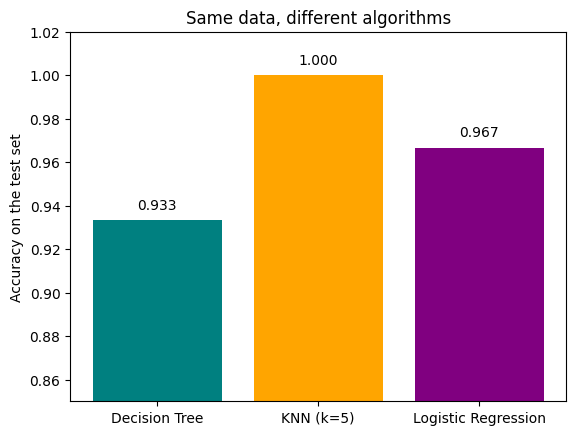

In [11]:
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
    "Logistic Regression": LogisticRegression(max_iter=1000),
}
results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    results[name] = accuracy_score(y_test, model.predict(X_test))
    print(f"{name:22s} accuracy = {results[name]:.4f}")

plt.bar(results.keys(), results.values(), color=["teal", "orange", "purple"])
plt.ylabel("Accuracy on the test set")
plt.title("Same data, different algorithms")
plt.ylim(0.85, 1.02)
for i, v in enumerate(results.values()):
    plt.text(i, v + 0.005, f"{v:.3f}", ha="center")
plt.show()

In [18]:
new_flowers = pd.DataFrame([
    [5.1, 3.5, 1.4, 0.2],   # small petals -> ?
    [6.7, 3.0, 5.2, 2.3],   # big petals  -> ?
], columns=iris.feature_names)

predicted = tree.predict(new_flowers)
for flower, species in zip(new_flowers.values, predicted):
    print(flower, "->", iris.target_names[species])

# --- TRY YOUR OWN: change these 4 numbers and run the cell again ---
my_flower = pd.DataFrame([[5.5, 3.0, 4.2, 1.2]], columns=iris.feature_names)
print("My flower ->", iris.target_names[tree.predict(my_flower)[0]])

[5.1 3.5 1.4 0.2] -> setosa
[6.7 3.  5.2 2.3] -> virginica
My flower -> versicolor
